# 04 - Evaluation

Evaluate the saved best model: ROC-AUC, classification report, confusion matrix, ROC curve, and feature importances for interpretability.

In [1]:
%load_ext autoreload
%autoreload 2

import pandas as pd
from src.config import PROCESSED_DATA_DIR
from src.models.train import split_data
from src.models.predict import load_model
from src.models.evaluate import evaluate_model
from src.models.explain import get_feature_importances
from src.visualization.visualize import plot_confusion_matrix, plot_roc_curve, plot_feature_importance

df = pd.read_csv(PROCESSED_DATA_DIR / "diabetic_data_clean.csv")
# Same RANDOM_STATE as 03_modeling -> identical split, so no need to persist it separately.
X_train, X_test, y_train, y_test = split_data(df)

model = load_model("best_model.joblib")

In [2]:
metrics = evaluate_model(model, X_test, y_test)
print(f"ROC-AUC: {metrics['roc_auc']:.3f}")
pd.DataFrame(metrics["classification_report"]).round(3)

ROC-AUC: 0.680


,0,1,accuracy,macro avg,weighted avg
precision,0.954,0.122,0.666,0.538,0.893
recall,0.672,0.583,0.666,0.628,0.666
f1-score,0.788,0.202,0.666,0.495,0.746
support,13063.000,1025.000,0.666,14088.000,14088.000


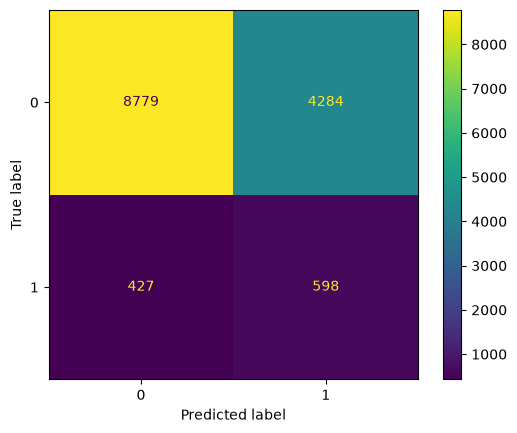

In [3]:
plot_confusion_matrix(model, X_test, y_test, save_as="04_confusion_matrix.png")

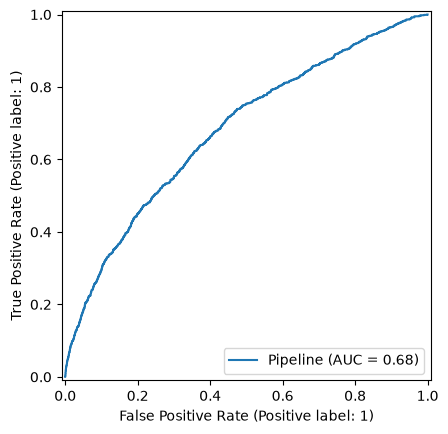

In [4]:
plot_roc_curve(model, X_test, y_test, save_as="04_roc_curve.png")

## Feature importance

Which features drive the model's predictions?

In [5]:
importances = get_feature_importances(model, top_n=15)
importances

,feature,importance
0,number_inpatient,0.355986
1,discharge_disposition_id_1,0.148557
2,discharge_disposition_id_22,0.062644
3,number_diagnoses,0.045908
4,num_lab_procedures,0.040529
5,num_medications,0.032540
6,discharge_disposition_id_3,0.027430
7,time_in_hospital,0.021992
8,discharge_disposition_id_5,0.019804
9,diag_1_cat_circulatory,0.014618


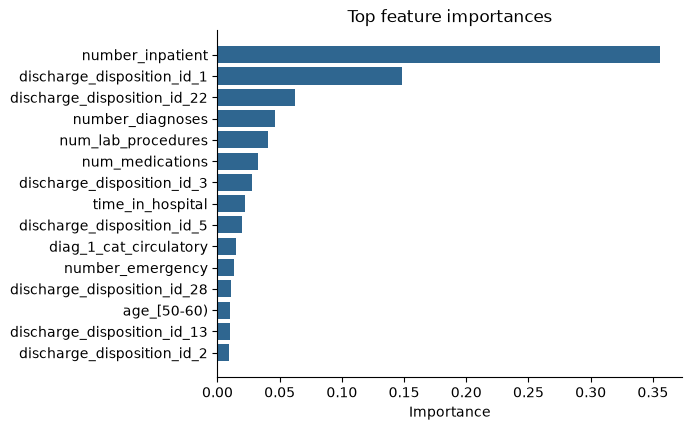

In [6]:
plot_feature_importance(importances, save_as="04_feature_importance.png")

Prior utilization (`number_inpatient`, `number_emergency`), `number_medications`, `time_in_hospital`, and `number_diagnoses` dominate — consistent with the EDA finding that patients with more prior hospital contact are readmitted more often. This also matches clinical intuition: complexity of care (more meds, more diagnoses, longer stays) and a history of utilization are the strongest signals, not demographics.